## 1. Cvxpy

- 필요 패키지는 `numpy`, `matplotlib`, `cvxpy`.
- 로컬 환경에 `cvxpy`가 없다면 터미널 또는 노트북 별도 셀에서 다음을 실행합니다.

```bash
pip install cvxpy numpy matplotlib
```

In [27]:
import numpy as np
import cvxpy as cp
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

print("CVXPY version:", cp.__version__)
print("Installed solvers:", cp.installed_solvers())

CVXPY version: 1.6.7
Installed solvers: ['CLARABEL', 'CVXOPT', 'GLPK', 'GLPK_MI', 'HIGHS', 'OSQP', 'SCIPY', 'SCS']


- cvxpy 라이브러리에서 제공하는 솔버는 위와 같으며, 필요시 외부 솔버를 추가로 설치 가능
- 현재 `CLARABEL`이 가장 최신 솔버로, 성능이 우수함

## 2. Convex optimization

- 일반적인 최적화 문제는 다음처럼 씀:
$$
\begin{aligned}
\min_x \quad & f_0(x) \\
\text{s.t.}\quad & f_i(x) \le 0, \quad i=1,\dots,m, \\
& h_j(x) = 0, \quad j=1,\dots,p.
\end{aligned}
$$

- 이 문제가 **convex optimization problem**이 되려면 보통 다음 조건을 만족해야 함:
  1. 목적함수 $f_0$는 convex function
  2. 부등식 제약 $f_i(x) \le 0$에서 $f_i$는 convex function
  3. 등식 제약 $h_j(x)=0$는 affine function, 즉 $h_j(x)=a_j^T x+b_j$

- Convex set과 convex function의 기본 정의는 다음과 같음.

### Convex set
- 집합 안의 두 점을 잇는 선분 전체가 다시 집합 안에 있다면 그 집합 $\mathcal{C}$는 convex set임:
$$
x,y\in\mathcal{C},\; \theta\in[0,1]
\quad\Rightarrow\quad
\theta x+(1-\theta)y\in\mathcal{C}.
$$

Example
  - Ball, box, half-space, second-order cone은 convex set임
  - 반면 $1\le \|x\|_2\le 2$와 같은 제약은 non-convex임

### Convex function
- 그래프 위 두 점을 이은 직선이 함수 그래프보다 위에 있다면 함수 $f$는 convex함:
$$
f(\theta x+(1-\theta)y)
\le
\theta f(x)+(1-\theta)f(y),
\quad \theta\in[0,1].
$$

- 두 번 미분 가능한 스칼라 함수라면 Hessian으로도 확인이 가능함:
$$
\nabla^2 f(x) \succeq 0 \quad \forall x
\quad\Rightarrow\quad
f \text{ is convex.}
$$

- Convex optimization으로 만드려는 이유는 다음과 같은 특징이 성립하기 때문:
  1. local optimum이 global optimum
  2. feasibility와 optimality를 비교적 안정적으로 판정 가능
  3. SOCP, QP 같은 cone program으로 바꾸면 검증된 solver를 사용 가능
  4. onboard guidance처럼 계산 시간이 중요한 문제에서 “예측 가능한 반복 구조”를 만들기 유용

### 2.1 CVXPY DCP rule

- `cvxpy`는 사용자가 쓴 수식이 **Disciplined Convex Programming, DCP** 규칙을 만족하는지 검사함.

- DCP rule의 대표적 조건은 다음과 같음:
  1. convex 목적함수는 minimize할 수 있은
  2. concave 목적함수는 maximize할 수 있음
  3. convex expression $\le$ concave expression 형태의 inequality가 허용됩니다.
  4. equality constraint는 affine equality만 허용됩니다.

Example
- 발사체의 추력은 다음과 같이 lower & upper bound가 주어짐:
$$
u_{\rm min}\le\|u\|_2 \le u_{\rm max}
$$

- upper bound 제약은 ball constraint로, feasible set이 convex set이므로 convex constraint임
$$
\|u\|_2 \le u_{\rm max}
$$

- 그러나 lower bound 제약은 반전된 ball constraint로, feasible set이 non-convex set이므로 non-convex constraint임
$$
\|u\|_2 \ge u_{\rm min}
$$

- cvxpy의 DCP rule에 따르면, 위 제약 조건은 다음과 같이 concave expression $\leq$ 0 꼴이므로 DCP rule을 위반하고, cvxpy에서 다룰 수 없음
$$
\underbrace{-\|u\|_2+u_{\rm min}}_{\rm concave} \le 0
$$

In [28]:
x = cp.Variable(2)

convex_problem = cp.Problem(
    cp.Minimize(cp.sum_squares(x)),
    [cp.norm(x, 2) <= 1.0]
)

nonconvex_problem = cp.Problem(
    cp.Minimize(cp.sum_squares(x)),
    [cp.norm(x, 2) >= 1.0]
)

print("Problem with ||x|| <= 1 is DCP:", convex_problem.is_dcp())
print("Problem with ||x|| >= 1 is DCP:", nonconvex_problem.is_dcp())

print("curvature of sum_squares(x):", cp.sum_squares(x).curvature)
print("curvature of norm(x):", cp.norm(x, 2).curvature)

Problem with ||x|| <= 1 is DCP: True
Problem with ||x|| >= 1 is DCP: False
curvature of sum_squares(x): CONVEX
curvature of norm(x): CONVEX


### 2.2 Toy example: Constrained least-squares

- 다음 문제는 가장 기본적인 least-squares 형태임:
$$
\begin{aligned}
\min_x \quad & \|Ax-b\|_2^2 \\
\text{s.t.}\quad & \|x\|_2 \le 1, \\
& x_1+x_2 \ge 0.2.
\end{aligned}
$$

- 목적함수는 convex quadratic이고, constraint는 second-order cone과 affine half-space임.

In [29]:
A = np.array([[1.0, 2.0],
              [2.0, 1.0],
              [1.0, -1.0]])
b = np.array([1.0, 0.5, 0.2])

x = cp.Variable(2)

objective = cp.Minimize(cp.sum_squares(A @ x - b))
constraints = [
    cp.norm(x, 2) <= 1.0,
    x[0] + x[1] >= 0.2,
]

problem = cp.Problem(objective, constraints)
print("DCP:", problem.is_dcp())

problem.solve(solver=cp.CLARABEL)

print("status:", problem.status)
print("optimal value:", problem.value)
print("x*:", x.value)

DCP: True
status: optimal
optimal value: 0.16333333333333333
x*: [0.2333 0.2667]


### 2.3. Toy example: 3-DOF point-mass minimum-energy control

- Optimal control 문제 또한 convex optimization의 대표적인 활용 예시임

- 선형 시스템의 optimal control 문제는 상태 변수에 대한 state space representation으로부터 구성할 수 있음

- 예시로, 가속도를 낼 수 있는 3차원 질점을 목표 상태로 만들기 위한 optimal control을 살펴보자.

- 상태 변수 및 제어 입력은 다음과 같음:
$$
r_k \in \mathbb{R}^3,\quad v_k\in\mathbb{R}^3,\quad u_k\in\mathbb{R}^3.
$$

- 여기서 $r$은 position, $v$는 velocity, $u$는 제어가 만드는 acceleration임

- 중력 $g$가 일정하다고 하면 continuous dynamics는
$$
\dot r = v,\qquad \dot v = u+g.
$$

- zero-order hold로 $u_k$가 구간 $[t_k,t_{k+1}]$에서 상수라고 가정하면 discrete dynamics는 다음과 같고, 이는 affine임:
$$
\begin{aligned}
r_{k+1} &= r_k + \Delta t\, v_k + \frac{1}{2}\Delta t^2 (u_k+g),\\
v_{k+1} &= v_k + \Delta t\,(u_k+g).
\end{aligned}
$$

- minimum-energy control 문제는 다음과 같이 구성:
$$
\begin{aligned}
\min_{r,v,u}\quad & \sum_{k=0}^{N-1} \Delta t\,\|u_k\|_2^2 \\
\text{s.t.}\quad
& r_{k+1}=r_k+\Delta t v_k + \frac{1}{2}\Delta t^2(u_k+g),\\
& v_{k+1}=v_k+\Delta t(u_k+g),\\
& r_0=r_{\text{init}},\quad v_0=v_{\text{init}},\\
& r_N=r_{\text{final}},\quad v_N=v_{\text{final}},\\
& \|u_k\|_2 \le u_{\max},\\
& e_3^T r_k \ge 0.
\end{aligned}
$$

- 이 문제는 convex하다
  - dynamics와 boundary condition은 affine equality
  - acceleration bound는 norm upper bound
  - floor constraint는 affine inequality
  - 목적함수는 convex quadratic

In [30]:
N = 60
tf = 12.0
dt = tf / N

g = np.array([0.0, 0.0, -1.62])  # lunar-like gravity, m/s^2

r_init = np.array([0.0, 0.0, 40.0])
v_init = np.array([0.0, 0.0, 0.0])

r_final = np.array([80.0, 50.0, 0.0])
v_final = np.array([0.0, 0.0, 0.0])

u_max = 6.0

r = cp.Variable((3, N + 1))
v = cp.Variable((3, N + 1))
u = cp.Variable((3, N))

constraints = [
    r[:, 0] == r_init,
    v[:, 0] == v_init,
    r[:, N] == r_final,
    v[:, N] == v_final,
]

for k in range(N):
    constraints += [
        r[:, k + 1] == r[:, k] + dt * v[:, k] + 0.5 * dt**2 * (u[:, k] + g),
        v[:, k + 1] == v[:, k] + dt * (u[:, k] + g),
        cp.norm(u[:, k], 2) <= u_max,
        r[2, k] >= 0.0,
    ]

constraints += [r[2, N] >= 0.0]

objective = cp.Minimize(dt * cp.sum_squares(u))
problem = cp.Problem(objective, constraints)

print("DCP:", problem.is_dcp())
problem.solve(solver=cp.CLARABEL)

print("status:", problem.status)
print("minimum energy:", problem.value)
print("max ||u||:", np.max(np.linalg.norm(u.value, axis=0)))

DCP: True
status: optimal
minimum energy: 104.4297269241464
max ||u||: 5.056902559393676


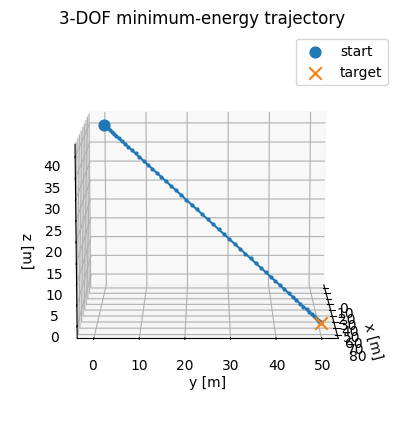

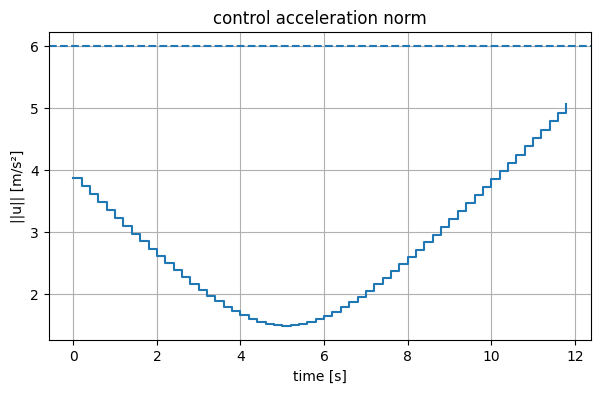

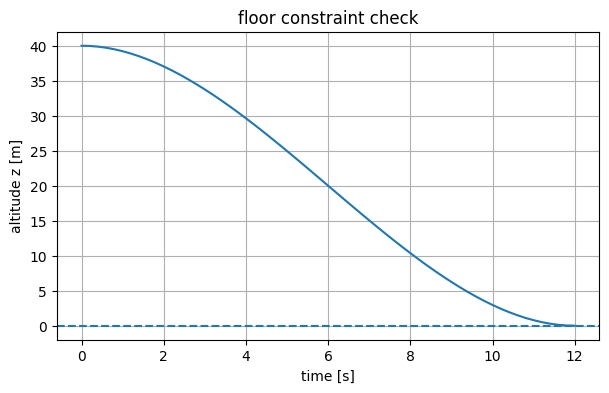

In [31]:
t = np.linspace(0.0, tf, N + 1)
r_sol = r.value
v_sol = v.value
u_sol = u.value

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")
ax.plot(r_sol[0, :], r_sol[1, :], r_sol[2, :], marker="o", markersize=2)
ax.scatter(r_init[0], r_init[1], r_init[2], marker="o", s=60, label="start")
ax.scatter(r_final[0], r_final[1], r_final[2], marker="x", s=80, label="target")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_zlabel("z [m]")
ax.set_title("3-DOF minimum-energy trajectory")
ax.legend()
ax.view_init(10, 0)
plt.show()

plt.figure(figsize=(7, 4))
plt.step(t[:-1], np.linalg.norm(u_sol, axis=0), where="post")
plt.axhline(u_max, linestyle="--")
plt.xlabel("time [s]")
plt.ylabel("||u|| [m/s²]")
plt.title("control acceleration norm")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(t, r_sol[2, :])
plt.axhline(0.0, linestyle="--")
plt.xlabel("time [s]")
plt.ylabel("altitude z [m]")
plt.title("floor constraint check")
plt.grid(True)
plt.show()

## 3. Sequential Convex Programming, SCP

- 현실적인 guidance 문제는 대개 다음 이유로 non-convex가 됨
  - nonlinear dynamics: $x_{k+1}=f(x_k,u_k)$
  - aerodynamic drag: $D(v)\propto \|v\|v$
  - mass coupling: $\dot v=T/m+g$, $\dot m=-\alpha\|T\|$
  - lower thrust bound: $\|T\|_2\ge T_{\min}$
  - obstacle avoidance: keep-out zone 바깥쪽 영역
  - attitude/gimbal/line-of-sight constraint와 translational dynamics의 결합

- Non-convex한 제약들을 강제하는 여러 방법들이 연구되고 있고, 그중 SCP가 일반적이고 직관적임
- SCP는 non-convex optimal control 문제를 한 번에 풀지 않고, 현재 기준 궤적 주변에서 convex subproblem을 반복해서 풀이함

- 일반적인 discrete nonlinear dynamics가
$$
x_{k+1}=f(x_k,u_k)
$$
라면, 기준 궤적 $(\bar x_k,\bar u_k)$ 주변에서 1차 근사함
$$
\begin{aligned}
x_{k+1}
&\approx
f(\bar x_k,\bar u_k)
+A_k(x_k-\bar x_k)+B_k(u_k-\bar u_k),\\
A_k &= \left.\frac{\partial f}{\partial x}\right|_{\bar x_k,\bar u_k},\qquad
B_k = \left.\frac{\partial f}{\partial u}\right|_{\bar x_k,\bar u_k}.
\end{aligned}
$$

- 실무적인 SCP subproblem은 보통 다음 요소를 포함:
$$
\begin{aligned}
\min\quad
& J_{\text{convex}}(x,u)
+ w_\nu \sum_k \|\nu_k\|_1
+ w_{\text{tr}} \sum_k \eta_k \\
\text{s.t.}\quad
& \underbrace{x_{k+1}=f(\bar x_k,\bar u_k)+A_k(x_k-\bar x_k)+B_k(u_k-\bar u_k)+\nu_k}_{\text{convexified constraints}},\\
& \|x_k-\bar x_k\| \le \Delta_x,\quad \|u_k-\bar u_k\|\le \Delta_u.
\end{aligned}
$$

- 여기서 $\nu_k$는 virtual control임
- 초기 reference가 나빠서 선형화 dynamics를 정확히 만족하기 어려울 때 infeasible이 되는 것을 막기 위한 장치
- Trust region은 선형화/근사가 믿을 수 있는 범위 안에서만 subproblem을 풀게 만듦

### 3.1 Lossless convexification

- SCP를 통해 선형화하면 convex constraint로 만들 수 있지만, 선형화하지 않고도 보조 변수 도입 및 차원 증강을 통해 convex constraint로 변환하는 방법들도 존재함

- 가령, Powered descent에서 thrust magnitude bound:
$$
T_{\min}\le \|T(t)\|_2 \le T_{\max}.
$$
에서 오른쪽 제약
$$
\|T(t)\|_2 \le T_{\max}
$$
은 convex지만, 왼쪽 제약
$$
\|T(t)\|_2 \ge T_{\min}
$$
은 ball 바깥쪽 영역이므로 non-convex임

- Lossless convexification의 핵심 패턴은 보조변수 $\Gamma$를 도입해 다음 relaxation을 만드는 것임
$$
\|T(t)\|_2 \le \Gamma(t),\qquad
T_{\min}\le \Gamma(t)\le T_{\max}.
$$

- 이 relaxation만 따로 보면 원래 문제와 같지 않음. 예를 들어 $T=0$, $\Gamma=T_{\min}$도 만족할 수 있기 때문

- 그러나 powered-descent minimum-fuel 문제의 dynamics와 목적함수 구조가 함께 있을 때, 특정 조건 아래에서는 최적해에서
$$
\|T^*(t)\|_2 = \Gamma^*(t)
$$
가 되어 relaxation이 원래 문제의 최적해를 잃지 않는다는 결과가 알려져 있음. “lossless”라는 이름은 이 때문에 붙여짐

- 이와 같은 lossless convexification을 비롯해, non-convex 제약들을 convex 제약으로 표현하는 트릭들은 다음과 같은 의미가 있음

> Non-convex 문제를 SCP로 무작정 선형화하기 전에, 문제 구조를 이용해 convex equivalent 또는 lossless relaxation을 찾으면 훨씬 안정적이고 빠른 guidance formulation이 됨

In [32]:
T = cp.Variable(3)
Gamma = cp.Variable(nonneg=True)
T_min = 5.0
T_max = 13.0

original_thrust_bound = cp.Problem(
    cp.Minimize(cp.sum_squares(T)),
    [cp.norm(T, 2) >= T_min,
     cp.norm(T, 2) <= T_max]
)

relaxed_thrust_bound = cp.Problem(
    cp.Minimize(Gamma),
    [cp.norm(T, 2) <= Gamma,
     T_min <= Gamma,
     Gamma <= T_max]
)

print("original bound is DCP:", original_thrust_bound.is_dcp())
print("relaxed bound is DCP:", relaxed_thrust_bound.is_dcp())

original bound is DCP: False
relaxed bound is DCP: True


## 4. SCP example: powered descent landing benchmark

- 이제 3-DOF powered descent landing 문제를 다뤄보자.

### 4.1 Benchmark parameter

- Açıkmeşe와 Ploen의 Mars landing 예제에서 사용된 대표 parameter를 사용함.
- 원 논문 좌표계는 중력이 첫 번째 축에 작용하도록 쓰지만, 여기서는 직관적이도록 다음 좌표계를 씀:
$$
r=[x,y,z]^T,
$$
여기서 $z$는 altitude이고, gravity는
$$
g=[0,0,-3.7114]^T\;\mathrm{m/s^2}
$$

- 원 논문의 glide-slope case
$$
r_0=[1.5,0,2]^T\;\mathrm{km},\qquad
\dot r_0=[-75,0,100]^T\;\mathrm{m/s}
$$
를 축만 바꾸어 다음처럼 씀:
$$
r_0=[2000,0,1500]^T\;\mathrm{m},\qquad
v_0=[100,0,-75]^T\;\mathrm{m/s}.
$$

- 질량과 추력 parameter는 다음과 같음:
$$
\begin{aligned}
m_{\mathrm{wet}} &= 1905\;\mathrm{kg},\\
m_{\mathrm{dry}} &= 1505\;\mathrm{kg},\\
I_{sp} &= 225\;\mathrm{s},\\
\bar T &= 3.1\;\mathrm{kN}\quad\text{per thruster},\\
T_1 &= 0.3\bar T,
\quad
T_2=0.8\bar T,\\
n &= 6,\\
\phi &= 27^\circ.
\end{aligned}
$$
여기서 $\phi$는 thruster cant angle

- Net thrust magnitude bound는
$$
\rho_1=n(0.3\bar T)\cos\phi,
\qquad
\rho_2=n(0.8\bar T)\cos\phi.
$$

- 원 논문은 glide-slope case에서 $t_f=81\;\mathrm{s}$, fuel usage 약 $399.5\;\mathrm{kg}$를 보고함.

- 본 예제는 discretization, fixed-final-time 처리, thrust-vector constraint 추가 때문에 숫자가 완전히 같지는 않을 수 있지만, 같은 modeling idea를 따르도록 함.

### 4.2 Continuous-time formulation

- 원래 translational powered descent dynamics는 다음과 같음:
$$
\dot r = v,
\qquad
\dot v = \frac{T}{m}+g,
\qquad
\dot m = -\alpha \|T\|_2.
$$
여기서
$$
\alpha=\frac{1}{I_{sp}g_e\cos\phi},
\qquad
 g_e = 9.807\;\mathrm{m/s^2}.
$$

- Fuel-optimal problem은 final mass를 최대화하는 것과 같으므로,
$$
\max m(t_f)
\quad\Longleftrightarrow\quad
\min m(0)-m(t_f).
$$

- 질량 변화율 자체는 추력 벡터의 L2-norm 항이 존재하므로 비선형임
- 또한, 속도 변화율에는 추력을 살태변수인 질량으로 나눈 비선형 항 존재, 이로 인해 동역학을 직접 선형화하더라도 분모 항으로 인해 수치적으로 불안정할 수 있음

- 따라서 다음과 같이 변수를 변환
$$
z=\log m,
\qquad
u=\frac{T}{m},
\qquad
\sigma \approx \frac{\|T\|_2}{m}.
$$

- 그러면 dynamics는 다음처럼 affine해짐:
$$
\dot r=v,
\qquad
\dot v=u+g,
\qquad
\dot z=-\alpha\sigma.
$$

- Lossless convexification relaxation은
$$
\|u\|_2\le \sigma
$$
임

- 추력 bound는
$$
\frac{\rho_1}{m}\le \sigma \le \frac{\rho_2}{m}
$$
이고 $m=e^z$이므로
$$
\rho_1e^{-z}\le \sigma\le \rho_2e^{-z}
$$
가 됨

- 왼쪽은 convex function의 epigraph 형태이지만, 오른쪽은 $\sigma\le\rho_2 e^{-z}$ 꼴이라 DCP가 아님

- 따라서 기준 trajectory $\bar z$ 주변에서 다음처럼 convex approximation하여 하한은 2차 Taylor 근사로 convex하게 변환:
$$
\rho_1 e^{-\bar z}
\left[1-(z-\bar z)+\frac{1}{2}(z-\bar z)^2\right]
\le \sigma.
$$

- 상한은 1차 Taylor 근사로 affine하게 변환
$$
\sigma
\le
\rho_2 e^{-\bar z}\left[1-(z-\bar z)\right].
$$

- 이제 각 SCP iteration에서 $\bar z$를 이전 solution으로 업데이트함

### 4.3 State/control constraints

- 연착륙 문제에 포함된 constraint는 다음과 같음

#### Boundary conditions

$$
r(0)=r_0,\quad v(0)=v_0,\quad z(0)=\log m_{\mathrm{wet}},
$$

$$
r(t_f)=0,
\qquad
v(t_f)=0.
$$

#### Mass bound

$$
\log m_{\mathrm{dry}}\le z_k\le \log m_{\mathrm{wet}}.
$$

#### Floor constraint

$$
z_{\mathrm{alt},k}\ge 0.
$$

#### Glide-slope constraint

- 착륙 지점이 원점일 때 수평거리와 altitude 사이에 다음 cone constraint를 강제

$$
\|r_{xy,k}\|_2 \le \frac{r_{z,k}}{\tan \gamma}.
$$

- 여기서 $\gamma=4^\circ$로 두면 원 논문의 $\hat\theta_{alt}=86^\circ$와 같은 의미로, 수평선 기준 4도 이상의 elevation cone 안에 있어야 하는 제약임
- 이 제약은 second order cone 제약이므로 convex한 제약임

#### Thrust-vector constraint

- 추력 방향이 수직축에서 너무 많이 기울지 않도록 다음 cone constraint를 강제
$$
u_{z,k}\ge \cos\theta_{\max}\,\sigma_k.
$$

- $\|u_k\|_2\le\sigma_k$도 함께 있으므로, 최적해에서 relaxation이 tight하면 thrust vector의 tilt angle이 $\theta_{\max}$ 이하가 됩니다.

In [63]:
N = 81
tf = 81.0
dt = tf / N

g_mars = np.array([0.0, 0.0, -3.7114])
g_earth = 9.807

m_wet = 1905.0
m_dry = 1505.0
Isp = 225.0
T_bar = 3.1e3
n_thrusters = 6.0
cant_angle = np.deg2rad(27.0)

rho_min = n_thrusters * 0.3 * T_bar * np.cos(cant_angle)
rho_max = n_thrusters * 0.8 * T_bar * np.cos(cant_angle)
alpha = 1.0 / (Isp * g_earth * np.cos(cant_angle))

r0 = np.array([2000.0, 0.0, 1500.0])
v0 = np.array([100.0, 0.0, -75.0])
rf = np.array([0.0, 0.0, 0.0])
vf = np.array([0.0, 0.0, 0.0])

log_m_wet = np.log(m_wet)
log_m_dry = np.log(m_dry)

glide_angle = np.deg2rad(4.0)
tilt_max = np.deg2rad(60.0)

print("rho_min [N]:", rho_min)
print("rho_max [N]:", rho_max)
print("rho_min / m_wet [m/s^2]:", rho_min / m_wet)
print("rho_max / m_wet [m/s^2]:", rho_max / m_wet)
print("alpha:", alpha)

rho_min [N]: 4971.816404971092
rho_max [N]: 13258.177079922916
rho_min / m_wet [m/s^2]: 2.6098773779375812
rho_max / m_wet [m/s^2]: 6.959673007833552
alpha: 0.0005086281851441083


### 4.4 SCP solve

- 아래 코드는 다음 과정을 반복
  1. 현재 기준 log-mass trajectory $\bar z_k$를 설정
  2. $\rho_1 e^{-z_k}\le\sigma_k\le\rho_2e^{-z_k}$를 $\bar z_k$ 주변에서 convex approximation
  3. 그 convex subproblem을 CVXPY로 풀이
  4. 새로 얻은 $z_k$를 다음 iteration의 reference로 사용

- 목적함수는
$$
\min \sum_{k=0}^{N-1}\Delta t\,\sigma_k
$$
이며, log-mass dynamics가
$$
z_{k+1}=z_k-\alpha\Delta t\sigma_k
$$
이므로, 이 목적함수를 줄이는 것은 final mass를 크게 만드는 것과 같음

In [54]:
m_ref = np.linspace(m_wet, m_dry + 20.0, N + 1)
z_ref = np.log(m_ref)

max_iters = 8
z_trust = 0.35
objective_history = []
fuel_history = []

for it in range(max_iters):
    r = cp.Variable((3, N + 1))
    v = cp.Variable((3, N + 1))
    z_mass = cp.Variable(N + 1)
    u = cp.Variable((3, N))
    sigma = cp.Variable(N, nonneg=True)

    constraints = [
        r[:, 0] == r0,
        v[:, 0] == v0,
        z_mass[0] == log_m_wet,
        r[:, N] == rf,
        v[:, N] == vf,
        z_mass >= log_m_dry,
        z_mass <= log_m_wet,
    ]

    for k in range(N):
        dz = z_mass[k] - z_ref[k]
        sigma_lower = rho_min * np.exp(-z_ref[k]) * (1.0 - dz + 0.5 * cp.square(dz))
        sigma_upper = rho_max * np.exp(-z_ref[k]) * (1.0 - dz)

        constraints += [
            r[:, k + 1] == r[:, k] + dt * v[:, k] + 0.5 * dt**2 * (u[:, k] + g_mars),
            v[:, k + 1] == v[:, k] + dt * (u[:, k] + g_mars),
            z_mass[k + 1] == z_mass[k] - alpha * dt * sigma[k],
            cp.norm(u[:, k], 2) <= sigma[k],
            sigma_lower <= sigma[k],
            sigma[k] <= sigma_upper,
            cp.abs(dz) <= z_trust,
            r[2, k] >= 0.0,
            cp.norm(r[0:2, k], 2) <= r[2, k] / np.tan(glide_angle),
            u[2, k] >= np.cos(tilt_max) * sigma[k],
        ]

    constraints += [
        r[2, N] >= 0.0,
        cp.norm(r[0:2, N], 2) <= r[2, N] / np.tan(glide_angle),
    ]

    objective = cp.Minimize(dt * cp.sum(sigma))
    problem = cp.Problem(objective, constraints)

    print("iteration", it, "DCP:", problem.is_dcp())
    problem.solve(solver=cp.CLARABEL, verbose=False)

    final_mass = np.exp(z_mass.value[-1])
    fuel_used = m_wet - final_mass
    objective_history.append(problem.value)
    fuel_history.append(fuel_used)

    print("  status:", problem.status)
    print("  objective:", problem.value)
    print("  fuel used [kg]:", fuel_used)

    z_new = z_mass.value.copy()
    z_ref = 0.7 * z_new + 0.3 * z_ref

    if len(objective_history) >= 2 and abs(objective_history[-1] - objective_history[-2]) <= 1e-3:
        break

r_pdl = r.value
v_pdl = v.value
z_pdl = z_mass.value
u_pdl = u.value
sigma_pdl = sigma.value
m_pdl = np.exp(z_pdl)

iteration 0 DCP: True
  status: optimal
  objective: 460.5682135487461
  fuel used [kg]: 397.84459865256963
iteration 1 DCP: True
  status: optimal
  objective: 460.5380687044839
  fuel used [kg]: 397.82148997773857
iteration 2 DCP: True
  status: optimal
  objective: 460.53536001942393
  fuel used [kg]: 397.81941351542696
iteration 3 DCP: True
  status: optimal
  objective: 460.53513004487473
  fuel used [kg]: 397.81923721844214


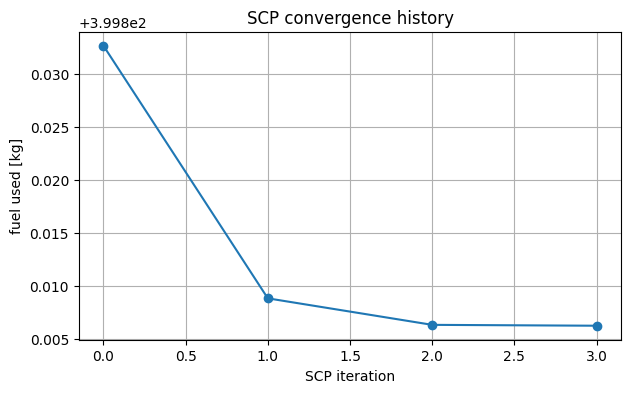

final fuel used [kg]: 399.80626946401685
final mass [kg]: 1505.1937305359831


In [35]:
plt.figure(figsize=(7, 4))
plt.plot(np.arange(len(fuel_history)), fuel_history, marker="o")
plt.xlabel("SCP iteration")
plt.ylabel("fuel used [kg]")
plt.title("SCP convergence history")
plt.grid(True)
plt.show()

print("final fuel used [kg]:", fuel_history[-1])
print("final mass [kg]:", m_pdl[-1])

### 4.5 Solution validation

- 최적해에 대해 다음을 검토
  - 궤적이 floor와 glide-slope cone을 만족하는가?
  - mass가 dry mass 아래로 떨어지지 않는가?
  - thrust magnitude가 lower/upper bound 안에 있는가?
  - thrust-vector tilt constraint가 만족되는가?
  - lossless relaxation이 실제로 tight한가, 즉 $\|u_k\|\approx \sigma_k$인가?

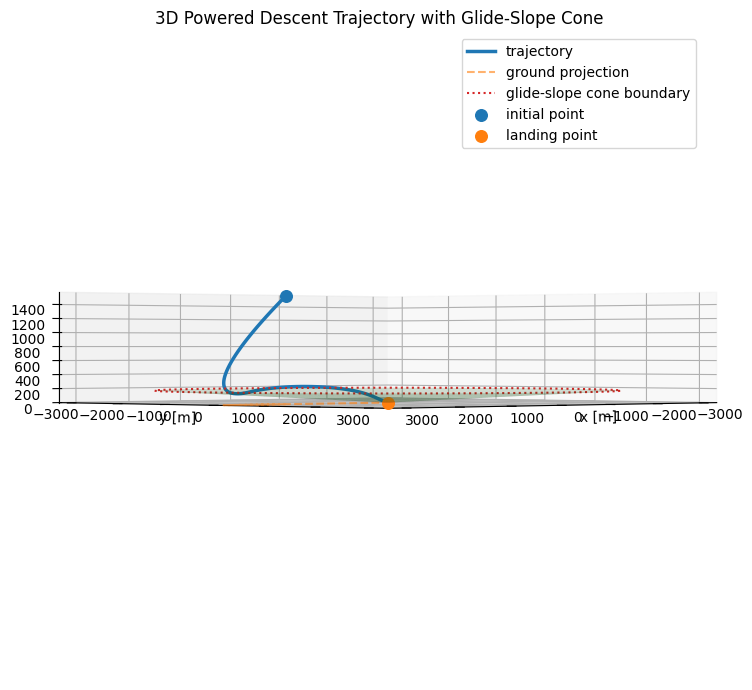

In [57]:
# @title
# Trajectory plot
from mpl_toolkits.mplot3d import Axes3D

t = np.linspace(0.0, tf, N + 1)
t_mid = t[:-1]

horizontal_range = np.linalg.norm(r_pdl[0:2, :], axis=0)
altitude = r_pdl[2, :]

range_grid = np.linspace(0.0, max(horizontal_range) * 1.05, 200)
glide_boundary = np.tan(glide_angle) * range_grid


x_traj = r_pdl[0, :]
y_traj = r_pdl[1, :]
z_traj = r_pdl[2, :]

# Glide-slope cone:
# z = tan(glide_angle) * sqrt(x^2 + y^2)
rho_max = np.max(np.linalg.norm(r_pdl[0:2, :], axis=0)) * 1.05

theta = np.linspace(0.0, 2.0 * np.pi, 100)
rho = np.linspace(0.0, rho_max, 80)

THETA, RHO = np.meshgrid(theta, rho)

X_cone = RHO * np.cos(THETA)
Y_cone = RHO * np.sin(THETA)
Z_cone = np.tan(glide_angle) * RHO

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# Trajectory
ax.plot(
    x_traj,
    y_traj,
    z_traj,
    linewidth=2.5,
    label="trajectory"
)

ax.plot(
    x_traj,
    y_traj,
    np.zeros_like(z_traj),
    linestyle="--",
    linewidth=1.5,
    alpha=0.6,
    label="ground projection"
)

ax.plot_surface(
    X_cone,
    Y_cone,
    Z_cone,
    alpha=0.18,
    linewidth=0
)

ax.plot(
    rho_max * np.cos(theta),
    rho_max * np.sin(theta),
    np.tan(glide_angle) * rho_max * np.ones_like(theta),
    linestyle=":",
    linewidth=1.5,
    label="glide-slope cone boundary"
)

ax.scatter(
    x_traj[0],
    y_traj[0],
    z_traj[0],
    s=70,
    label="initial point"
)

ax.scatter(
    x_traj[-1],
    y_traj[-1],
    z_traj[-1],
    s=70,
    label="landing point"
)

# Axes labels
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_zlabel("z [m]")
ax.set_title("3D Powered Descent Trajectory with Glide-Slope Cone")

# Make x-y limits symmetric around the landing site
xy_lim = rho_max
z_lim = max(np.max(z_traj), np.max(Z_cone)) * 1.05

ax.set_xlim(-xy_lim, xy_lim)
ax.set_ylim(-xy_lim, xy_lim)
ax.set_zlim(0.0, z_lim)

# More visually balanced 3D scaling
ax.set_box_aspect((2 * xy_lim, 2 * xy_lim, z_lim))

ax.legend()
ax.view_init(elev=0, azim=45)

plt.tight_layout()
plt.show()

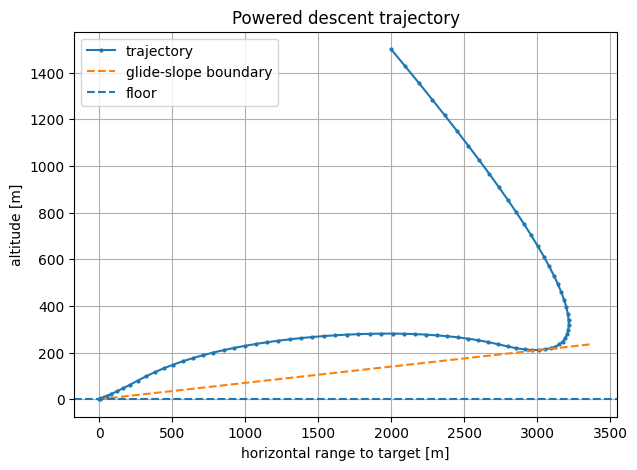

In [37]:
# @title
# Trajectory plot: horizontal range vs altitude

t = np.linspace(0.0, tf, N + 1)
t_mid = t[:-1]

horizontal_range = np.linalg.norm(r_pdl[0:2, :], axis=0)
altitude = r_pdl[2, :]

range_grid = np.linspace(0.0, max(horizontal_range) * 1.05, 200)
glide_boundary = np.tan(glide_angle) * range_grid

plt.figure(figsize=(7, 5))
plt.plot(horizontal_range, altitude, marker="o", markersize=2, label="trajectory")
plt.plot(range_grid, glide_boundary, linestyle="--", label="glide-slope boundary")
plt.axhline(0.0, linestyle="--", label="floor")
plt.xlabel("horizontal range to target [m]")
plt.ylabel("altitude [m]")
plt.title("Powered descent trajectory")
plt.grid(True)
plt.legend()
plt.show()

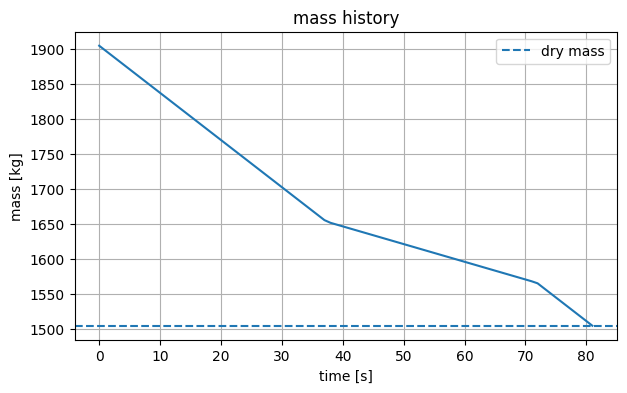

In [38]:
# @title
# Mass history

plt.figure(figsize=(7, 4))
plt.plot(t, m_pdl)
plt.axhline(m_dry, linestyle="--", label="dry mass")
plt.xlabel("time [s]")
plt.ylabel("mass [kg]")
plt.title("mass history")
plt.grid(True)
plt.legend()
plt.show()

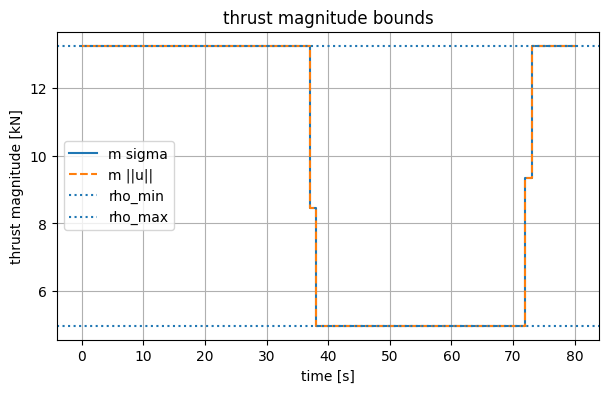

max relaxation gap sigma - ||u||: -9.523026121449618e-06
mean relaxation gap sigma - ||u||: -1.1742341362594342e-05


In [66]:
# @title
# Thrust magnitude and bounds

u_norm = np.linalg.norm(u_pdl, axis=0)
T_relaxed = sigma_pdl * m_pdl[:-1]
T_actual_like = u_norm * m_pdl[:-1]

plt.figure(figsize=(7, 4))
plt.step(t_mid, T_relaxed / 1000.0, where="post", label="m sigma")
plt.step(t_mid, T_actual_like / 1000.0, where="post", linestyle="--", label="m ||u||")
plt.axhline(rho_min / 1000.0, linestyle=":", label="rho_min")
plt.axhline(rho_max / 1000.0, linestyle=":", label="rho_max")
plt.xlabel("time [s]")
plt.ylabel("thrust magnitude [kN]")
plt.title("thrust magnitude bounds")
plt.grid(True)
plt.legend()
plt.show()

print("max relaxation gap sigma - ||u||:", np.max(sigma_pdl - u_norm))
print("mean relaxation gap sigma - ||u||:", np.mean(sigma_pdl - u_norm))

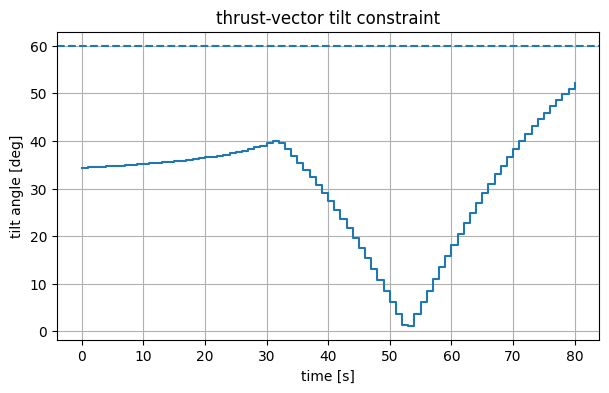

max tilt angle [deg]: 52.07331886421502


In [40]:
# @title
# Thrust tilt angle

cos_tilt = u_pdl[2, :] / np.maximum(np.linalg.norm(u_pdl, axis=0), 1e-9)
cos_tilt = np.clip(cos_tilt, -1.0, 1.0)
tilt_angle = np.rad2deg(np.arccos(cos_tilt))

plt.figure(figsize=(7, 4))
plt.step(t_mid, tilt_angle, where="post")
plt.axhline(np.rad2deg(tilt_max), linestyle="--")
plt.xlabel("time [s]")
plt.ylabel("tilt angle [deg]")
plt.title("thrust-vector tilt constraint")
plt.grid(True)
plt.show()

print("max tilt angle [deg]:", np.max(tilt_angle))

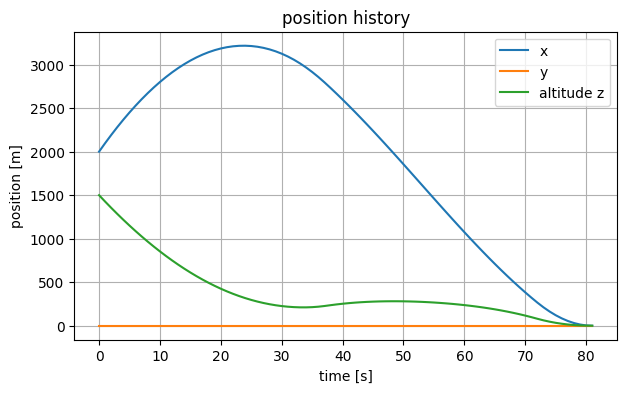

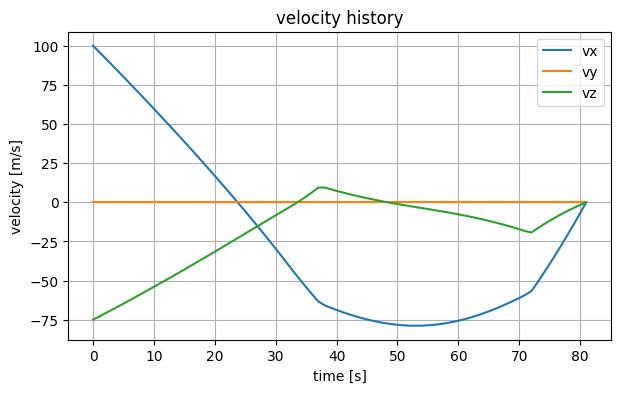

In [41]:
# @title
# Position and velocity components

plt.figure(figsize=(7, 4))
plt.plot(t, r_pdl[0, :], label="x")
plt.plot(t, r_pdl[1, :], label="y")
plt.plot(t, r_pdl[2, :], label="altitude z")
plt.xlabel("time [s]")
plt.ylabel("position [m]")
plt.title("position history")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(t, v_pdl[0, :], label="vx")
plt.plot(t, v_pdl[1, :], label="vy")
plt.plot(t, v_pdl[2, :], label="vz")
plt.xlabel("time [s]")
plt.ylabel("velocity [m/s]")
plt.title("velocity history")
plt.grid(True)
plt.legend()
plt.show()

## 5. Appendix

- SCP의 장점은 non-convex한 제약들을 선형화하여 convex한 제약으로 만들고, 이를 포함한 convex subproblem을 반복적으로 풀어 feasible한 해를 얻을 수 있다는 것임
- 그러나, 그만큼 SCP의 단점이 존재함

### Initial reference
- 초기 reference 궤적이 최적 궤적에서 너무 벗어난 궤적이라면, 초반에 subproblem의 해가 존재하지 않을 수 있음
- 이를 완화하기 위해 virtual control을 적용해 초반엔 동역학을 위반하더라도 구속 조건을 만족하는 해를 강제로 산출하도록 할 수 있음
- 혹은, 초반엔 만족시키기 어려운 구속 조건의 경우 slack 변수를 도입하여 완화할 수 있음
$$
h(x)\leq 0 \to h(x)\leq s,\quad \min \cdots + w_s \sum \|s\|^2
$$


### Crawling
- 초기 reference 궤적이 최적 궤적에서 크게 벗어난 궤적일 때, 최종 궤적에 도달할 때까지 SCP iteration을 반복하는데, 기준 궤적으로부터 trust region을 벗어나지 않도록 하기 위해 조금씩 변화함
- trust region이 고정되어 있다면 이 궤적이 변화하는 속도가 느려 많은 SCP iteration이 요구되는 문제가 존재
- 이를 완화하기 위해 선형화 오차를 비교해 오차가 적은 경우 trust region을 늘리고, 그 반대엔 줄이는 adaptive trust region 기법을 적용할 수 있음



### 5.1 Slack variable

- SCP subproblem이 infeasible하여 문제를 풀지 못하는 문제를 완화하는 방법 중 하나인 slack variable을 적용해보자.

- 가령, 위 benchmark에선 초기 속도로 인해 glide slope 제한각을 4deg보다 더 크게 설정하면 처음부터 subproblem을 푸는데 실패함
- 따라서 문제를 푸는데 실패하여도 이러한 제약 때문에 불가능한 조건임을 확인하기 어려움

- 이를 확인하는 방법으로, glide slope 제약의 우변에 0 대신 slack 변수를 두자.
- 그리고 목적 함수는 이 slack 변수를 줄이도록 패널티를 추가하자.
- 그렇다면, subproblem은 slack 변수가 있으므로 구속 조건을 강제할 수 있고, infeasible하여 SCP iteration을 진행하지 못하는 문제를 완화할 수 있음

- 확인할 사항은, 수렴된 최종 궤적에서, slack 변수가 0이 되었는가임, slack이 더이상 줄지 않는다면, 그 제약이 물리적으로 만족할 수 있는 한계라는 것을 의미함

In [81]:
N = 81
tf = 81.0
dt = tf / N

g_mars = np.array([0.0, 0.0, -3.7114])
g_earth = 9.807

m_wet = 1905.0
m_dry = 1505.0
Isp = 225.0
T_bar = 3.1e3
n_thrusters = 6.0
cant_angle = np.deg2rad(27.0)

rho_min = n_thrusters * 0.3 * T_bar * np.cos(cant_angle)
rho_max = n_thrusters * 0.8 * T_bar * np.cos(cant_angle)
alpha = 1.0 / (Isp * g_earth * np.cos(cant_angle))

r0 = np.array([2000.0, 0.0, 1500.0])
v0 = np.array([100.0, 0.0, -75.0])
rf = np.array([0.0, 0.0, 0.0])
vf = np.array([0.0, 0.0, 0.0])

log_m_wet = np.log(m_wet)
log_m_dry = np.log(m_dry)

#################
glide_angle = np.deg2rad(5.0)
#################
tilt_max = np.deg2rad(60.0)

In [83]:
m_ref = np.linspace(m_wet, m_dry + 20.0, N + 1)
z_ref = np.log(m_ref)

max_iters = 8
z_trust = 0.35
objective_history = []
fuel_history = []
g_slack_history = []

for it in range(max_iters):
    r = cp.Variable((3, N + 1))
    v = cp.Variable((3, N + 1))
    z_mass = cp.Variable(N + 1)
    u = cp.Variable((3, N))
    sigma = cp.Variable(N, nonneg=True)

    ################
    glide_slack = cp.Variable(N + 1, nonneg=True)
    ################

    constraints = [
        r[:, 0] == r0,
        v[:, 0] == v0,
        z_mass[0] == log_m_wet,
        r[:, N] == rf,
        v[:, N] == vf,
        z_mass >= log_m_dry,
        z_mass <= log_m_wet,
    ]

    for k in range(N):
        dz = z_mass[k] - z_ref[k]
        sigma_lower = rho_min * np.exp(-z_ref[k]) * (1.0 - dz + 0.5 * cp.square(dz))
        sigma_upper = rho_max * np.exp(-z_ref[k]) * (1.0 - dz)

        constraints += [
            r[:, k + 1] == r[:, k] + dt * v[:, k] + 0.5 * dt**2 * (u[:, k] + g_mars),
            v[:, k + 1] == v[:, k] + dt * (u[:, k] + g_mars),
            z_mass[k + 1] == z_mass[k] - alpha * dt * sigma[k],
            cp.norm(u[:, k], 2) <= sigma[k],
            sigma_lower <= sigma[k],
            sigma[k] <= sigma_upper,
            cp.abs(dz) <= z_trust,
            r[2, k] >= 0.0,
            ################
            cp.norm(r[0:2, k], 2) <= r[2, k] / np.tan(glide_angle) + glide_slack[k],
            ################
            u[2, k] >= np.cos(tilt_max) * sigma[k],
        ]

    ################
    constraints += [
        r[2, N] >= 0.0,
        cp.norm(r[0:2, N], 2) <= r[2, N] / np.tan(glide_angle) + glide_slack[N],
    ]
    ################

    ################
    glide_slack_weight = 100.0
    objective = cp.Minimize(
        dt * cp.sum(sigma) + glide_slack_weight * cp.sum(glide_slack)
    )
    ################

    problem = cp.Problem(objective, constraints)

    print("iteration", it, "DCP:", problem.is_dcp())
    problem.solve(solver=cp.CLARABEL, verbose=False)

    final_mass = np.exp(z_mass.value[-1])
    fuel_used = m_wet - final_mass
    objective_history.append(problem.value)
    fuel_history.append(fuel_used)
    g_slack_history.append(np.max(glide_slack.value))

    print("  status:", problem.status)
    print("  objective:", problem.value)
    print("  fuel used [kg]:", fuel_used)

    z_new = z_mass.value.copy()
    z_ref = 0.7 * z_new + 0.3 * z_ref

    if len(objective_history) >= 2 and abs(objective_history[-1] - objective_history[-2]) <= 1e-3:
        break

r_pdl = r.value
v_pdl = v.value
z_pdl = z_mass.value
u_pdl = u.value
sigma_pdl = sigma.value
m_pdl = np.exp(z_pdl)

iteration 0 DCP: True
  status: optimal
  objective: 454732.8837204884
  fuel used [kg]: 399.7672531533076
iteration 1 DCP: True
  status: optimal
  objective: 448725.0951595638
  fuel used [kg]: 399.9845410119665
iteration 2 DCP: True
  status: optimal
  objective: 446884.5996052894
  fuel used [kg]: 399.67100885806985
iteration 3 DCP: True
  status: optimal
  objective: 447831.9270994137
  fuel used [kg]: 399.9893160310669
iteration 4 DCP: True
  status: optimal
  objective: 446416.72657062346
  fuel used [kg]: 399.644738953609
iteration 5 DCP: True
  status: optimal
  objective: 447809.3069190429
  fuel used [kg]: 399.9920567917684
iteration 6 DCP: True
  status: optimal
  objective: 447751.1652461893
  fuel used [kg]: 399.97792692914027
iteration 7 DCP: True
  status: optimal
  objective: 447745.9067679706
  fuel used [kg]: 399.97705924530806


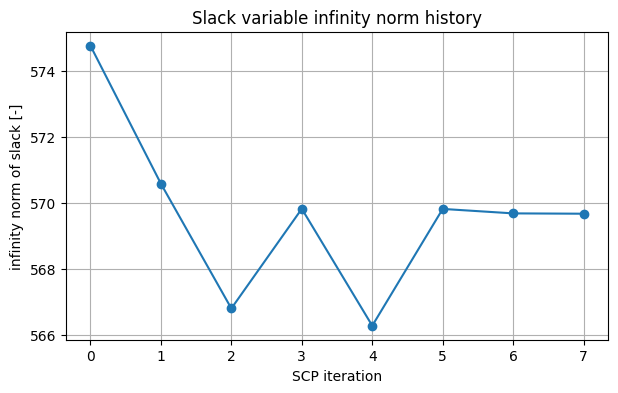

In [87]:
plt.figure(figsize=(7, 4))
plt.plot(np.arange(len(g_slack_history)), g_slack_history, marker="o")
plt.xlabel("SCP iteration")
plt.ylabel("infinity norm of slack [-]")
plt.title("Slack variable infinity norm history")
plt.grid(True)
plt.show()

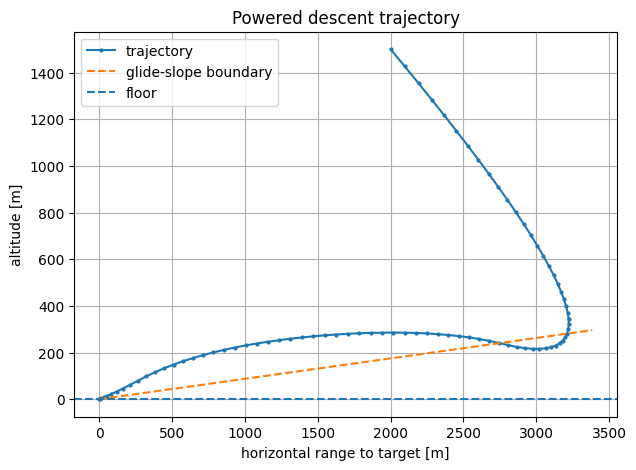

In [80]:
# @title
# Trajectory plot: horizontal range vs altitude

t = np.linspace(0.0, tf, N + 1)
t_mid = t[:-1]

horizontal_range = np.linalg.norm(r_pdl[0:2, :], axis=0)
altitude = r_pdl[2, :]

range_grid = np.linspace(0.0, max(horizontal_range) * 1.05, 200)
glide_boundary = np.tan(glide_angle) * range_grid

plt.figure(figsize=(7, 5))
plt.plot(horizontal_range, altitude, marker="o", markersize=2, label="trajectory")
plt.plot(range_grid, glide_boundary, linestyle="--", label="glide-slope boundary")
plt.axhline(0.0, linestyle="--", label="floor")
plt.xlabel("horizontal range to target [m]")
plt.ylabel("altitude [m]")
plt.title("Powered descent trajectory")
plt.grid(True)
plt.legend()
plt.show()

- 위 결과를 보면 slack이 더이상 줄지 않는 것을 확인할 수 있음
- 이로부터, glide slope각을 더 키우면 infeasible한, 즉 물리적으로 가능한 궤적이 나오지 못함을 간접적으로 확인할 수 있음

## 6. Remark points

### 6.1 Convexity?

- 원래 문제에는 다음 non-convex 구조가 있음:
$$
\dot v = \frac{T}{m}+g
$$
는 $T/m$ 때문에 nonlinear.

- 또한
$$
T_{\min}\le \|T\|_2
$$
는 norm lower bound라서 feasible set이 non-convex.

- 그리고 log-mass 변수 변환 후에도
$$
\sigma \le \rho_2 e^{-z}
$$
는 affine expression이 convex function보다 작다는 형태라 DCP가 아님.

### 6.2 Techniques

1. **변수 변환**

- 변수를 변환하여 dynamics를 affine하게 변환함:
$$
z=\log m,
\qquad
u=\frac{T}{m},
\qquad
\sigma\approx\frac{\|T\|}{m}
$$


2. **Lossless convexification**

$$
\|u\|_2\le\sigma
$$
를 사용해 thrust norm을 SOC constraint로 변환.

3. **SCP / successive approximation**

$$
\rho_1e^{-z}\le\sigma\le\rho_2e^{-z}
$$
에서 $e^{-z}$ 항을 기준 $\bar z$ 주변에서 convex/affine approximation하여 convex constraint로 변환, 이를 반복해 풀이하여 non-convex 제약을 다룸.

4. **Cone constraints**

- Glide slope와 thrust-vector tilt는 모두 convex한 second order cone 또는 affine cone 형태로 표현함:
$$
\|r_{xy}\|_2\le \frac{r_z}{\tan\gamma},
\qquad
u_z\ge \cos\theta_{\max}\sigma.
$$

## 8. References

- S. Boyd and L. Vandenberghe, *Convex Optimization*, Cambridge University Press, 2004.
- S. Diamond and S. Boyd, “CVXPY: A Python-Embedded Modeling Language for Convex Optimization,” *Journal of Machine Learning Research*, 2016.  
  https://www.jmlr.org/papers/volume17/15-408/15-408.pdf
- CVXPY documentation, “Disciplined Convex Programming.”  
  https://www.cvxpy.org/tutorial/dcp/
- B. Açıkmeşe and S. R. Ploen, “Convex Programming Approach to Powered Descent Guidance for Mars Landing,” *Journal of Guidance, Control, and Dynamics*, 30(5), 1353–1366, 2007.  
  https://doi.org/10.2514/1.27553
- J. M. Carson III, B. Açıkmeşe, and L. Blackmore, “Lossless Convexification of Powered-Descent Guidance with Non-Convex Thrust Bound and Pointing Constraints,” *American Control Conference*, 2011.  
  https://www.larsblackmore.com/CarsonAcikmeseBlackmoreACC11.pdf
- T. P. Reynolds, D. Malyuta, M. Mesbahi, B. Açıkmeşe, and J. M. Carson III, “A Real-Time Algorithm for Non-Convex Powered Descent Guidance,” AIAA SciTech, 2020.  
  https://depts.washington.edu/uwrainlab/wordpress/wp-content/uploads/2020/01/AIAA_SciTech_2020.pdf